# Weather in 30 Indian cities, 2021 to 2025

This notebook works through the questions we asked of the data, one at a time. Each section has the code, the chart or table it produces, and what we noticed. Where an official source covers the same ground, we compare our numbers with it.

The data is daily weather from the [Open-Meteo Historical Weather API](https://open-meteo.com/en/docs/historical-weather-api), prepared by `scripts/clean_data.py`.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e4e3df", "axes.axisbelow": True})
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"

weather = pd.read_csv("../data/processed/weather_clean.csv", parse_dates=["date"])
print(weather.shape)
weather.head()

(54780, 17)


,city,date,temp_mean_c,temp_max_c,temp_min_c,humidity_pct,pressure_hpa,wind_speed_kmh,wind_direction_deg,rain_mm,weather_code,year,month,season,weather,latitude,longitude
0,Agra,2021-01-01,12.2,20.2,5.0,69,1017.7,6.1,77,0.0,3,2021,1,Winter,Overcast,27.1767,78.0081
1,Agra,2021-01-02,14.9,20.9,10.3,71,1016.3,8.4,107,1.1,51,2021,1,Winter,Drizzle,27.1767,78.0081
2,Agra,2021-01-03,16.6,21.6,12.8,84,1014.4,10.4,94,6.9,55,2021,1,Winter,Drizzle,27.1767,78.0081
3,Agra,2021-01-04,18.5,25.1,14.5,81,1015.1,10.3,104,0.8,51,2021,1,Winter,Drizzle,27.1767,78.0081
4,Agra,2021-01-05,19.1,24.6,14.4,77,1015.0,8.8,117,0.1,3,2021,1,Winter,Overcast,27.1767,78.0081


## 1. Is the data fit to use?

Before any chart, we check that every city has every day, that nothing is missing, and that the values stay inside physical limits.

In [2]:
days_per_city = weather.groupby("city")["date"].nunique()
print("cities:", weather["city"].nunique())
print("days per city:", days_per_city.min(), "to", days_per_city.max())
print("missing values:", int(weather.isna().sum().sum()))
print("duplicate city and date rows:", int(weather.duplicated(["city", "date"]).sum()))
weather[["temp_mean_c", "humidity_pct", "pressure_hpa", "wind_speed_kmh", "rain_mm"]].describe().round(1)

cities: 30
days per city: 1826 to 1826
missing values: 0
duplicate city and date rows: 0


,temp_mean_c,humidity_pct,pressure_hpa,wind_speed_kmh,rain_mm
count,54780.0,54780.0,54780.0,54780.0,54780.0
mean,25.2,65.7,1008.9,9.2,3.4
std,6.1,19.0,6.0,3.9,9.3
min,-8.2,6.0,986.9,1.4,0.0
25%,22.3,53.0,1004.3,6.4,0.0
50%,26.4,70.0,1009.0,8.4,0.0
75%,29.0,81.0,1013.6,11.2,2.1
max,40.3,99.0,1037.4,44.0,330.3


All 30 cities have all 1,826 days, nothing is missing, and the ranges look physical: humidity stays between 0 and 100, rain is never negative, and sea-level pressure stays near 1,000 hPa.

These are model values for a grid cell, not readings from a weather station. Open-Meteo blends ERA5 (about 25 km cells), ERA5-Land (about 11 km) and the ECMWF IFS model (9 km), according to its [documentation](https://open-meteo.com/en/docs/historical-weather-api). Section 4 shows what that means for extremes.

## 2. How does temperature move through the year?

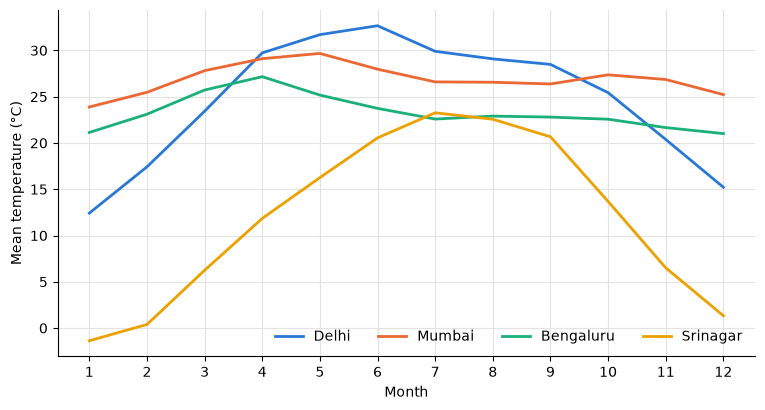

gap between warmest and coolest month (°C):
city
Madurai      5.2
Chennai      5.5
Mumbai       5.8
Ludhiana    21.0
Amritsar    21.6
Srinagar    24.6
dtype: float64


In [3]:
monthly = weather.groupby(["city", "month"])["temp_mean_c"].mean().unstack("city")
cities = {"Delhi": BLUE, "Mumbai": ORANGE, "Bengaluru": AQUA, "Srinagar": YELLOW}

fig, ax = plt.subplots()
for city, colour in cities.items():
    ax.plot(monthly.index, monthly[city], color=colour, linewidth=2, label=city)
ax.set_xticks(range(1, 13))
ax.set_xlabel("Month")
ax.set_ylabel("Mean temperature (°C)")
ax.legend(frameon=False, ncols=4)
plt.show()

swing = (monthly.max() - monthly.min()).sort_values()
print("gap between warmest and coolest month (°C):")
print(swing.round(1).iloc[[0, 1, 2, -3, -2, -1]])

Delhi peaks in June, not July. Once the monsoon arrives, cloud and rain cool it by about three degrees even though it is midsummer. Mumbai and Bengaluru barely move: Mumbai's warmest and coolest months are less than six degrees apart. Srinagar goes from below freezing in January to 23 °C in July.

The sea is the main reason. Coastal and southern cities have the smallest gap between their warmest and coolest month, and the inland north has the largest.

## 3. When does the rain fall?

In [4]:
total = weather.groupby("city")["rain_mm"].sum()
june_to_sept = weather[weather["season"] == "Monsoon"].groupby("city")["rain_mm"].sum()
oct_to_dec = weather[weather["month"] >= 10].groupby("city")["rain_mm"].sum()

print(f"share of all rain in June to September: {june_to_sept.sum() / total.sum():.0%}")
shares = pd.DataFrame({"June to September (%)": june_to_sept / total * 100,
                       "October to December (%)": oct_to_dec / total * 100}).round(0)
shares.sort_values("October to December (%)", ascending=False).head(5)

share of all rain in June to September: 74%


,June to September (%),October to December (%)
city,,
Chennai,32.0,57.0
Madurai,26.0,51.0
Bengaluru,51.0,30.0
Visakhapatnam,65.0,26.0
Vijayawada,64.0,18.0


Across the 30 cities, 74% of the rain falls from June to September. The India Meteorological Department puts the national figure at about 75% ([IMD Monsoon Report 2025, preface](https://mausam.imd.gov.in/imd_latest/monsoon_report_2025_2.pdf)), so our sample of cities agrees with the country as a whole.

Chennai and Madurai are the exceptions. They get more than half of their rain from October to December. IMD's Chennai office gives the same picture for Tamil Nadu: 48% of the state's annual rain comes from the north-east monsoon in those three months, because the state sits in a rain shadow during the south-west monsoon ([IMD Chennai, North-East Monsoon 2022 report](https://mausam.imd.gov.in/chennai/mcdata/ne_monsoon_2022.pdf)).

## 4. Was 2024 unusual?

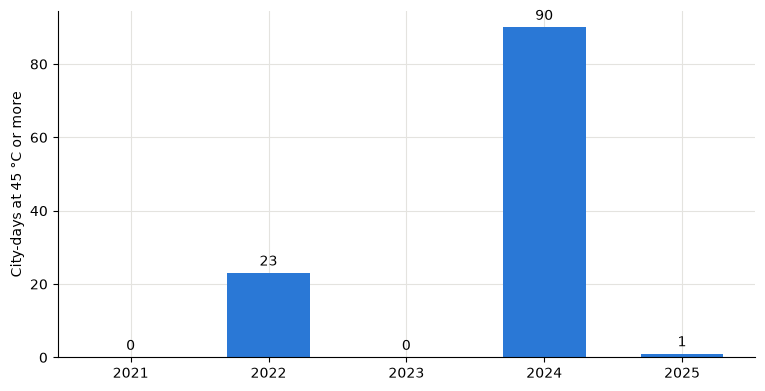

May 2024: 64 city-days in 15 cities
     city       date  temp_max_c
  Gwalior 2024-05-28        48.0
Prayagraj 2024-05-28        47.5
   Kanpur 2024-05-29        47.4


In [5]:
hot = weather[weather["temp_max_c"] >= 45]
heat_days = hot.groupby("year").size().reindex(range(2021, 2026), fill_value=0)

fig, ax = plt.subplots()
bars = ax.bar(heat_days.index.astype(str), heat_days.values, color=BLUE, width=0.6)
ax.bar_label(bars, padding=3)
ax.set_ylabel("City-days at 45 °C or more")
plt.show()

may_2024 = hot[(hot["year"] == 2024) & (hot["month"] == 5)]
print(f"May 2024: {len(may_2024)} city-days in {may_2024['city'].nunique()} cities")
print(may_2024.nlargest(3, "temp_max_c")[["city", "date", "temp_max_c"]].to_string(index=False))

Yes. 2024 had 90 city-days at 45 °C or more, against 23 in 2022 and none or almost none in the other three years. 64 of them fell in May 2024, spread over 15 cities. The hottest value anywhere in our data is 48.0 °C in Gwalior on 28 May 2024.

On that same day IMD stations recorded 50.5 °C in Churu and 49.9 °C at Mungeshpur in Delhi ([AIR News, 28 May 2024](https://www.newsonair.gov.in/several-parts-of-country-continues-to-reel-under-severe-heat-wave-conditions-breaking-past-records)). Our value for Delhi that day is 45.8 °C. The gap is expected: a model cell averages a whole area, so it smooths out the hottest spots that a single thermometer catches. Our data is good for comparing cities and years, and it understates the peaks.

In [6]:
yearly = weather.groupby("year")["temp_mean_c"].mean()
warmest_year = weather.groupby(["year", "city"])["temp_mean_c"].mean().unstack().idxmax()
print(yearly.round(2).to_string())
print()
print("number of cities whose warmest year it was:")
print(warmest_year.value_counts().sort_index().to_string())

year
2021    24.93
2022    25.01
2023    25.02
2024    25.37
2025    25.46

number of cities whose warmest year it was:
2021     1
2022     3
2023     3
2024     8
2025    15


The average across all cities rose every year, from 24.93 °C in 2021 to 25.46 °C in 2025, and 2025 was the warmest year for half of the cities. IMD reported 2024 as India's warmest year since national records began in 1901, at 0.65 °C above the 1991 to 2020 average ([IMD Annual Report 2024](https://metnet.imd.gov.in/docs/imdnews/ANNUAL_REPORT2024English.pdf)).

Five years is too short to call this a trend on our own data. What we can say is that our numbers point the same way as the official record.

## 5. Did our data see the strong 2024 monsoon?

In [7]:
monsoon = weather[weather["season"] == "Monsoon"].groupby(["year", "city"])["rain_mm"].sum().unstack()
by_year = monsoon.mean(axis=1)
print(by_year.round(0).to_string())
print(f"2024 against the five-year average: {by_year[2024] / by_year.mean():.0%}")

compared = (monsoon.loc[2024] / monsoon.mean()).sort_values()
print()
print("2024 against each city's own average:")
print(compared.iloc[[0, 1, 2, -3, -2, -1]].map("{:.0%}".format).to_string())
print("Guwahati:", f"{compared['Guwahati']:.0%}")

year
2021     889.0
2022     926.0
2023     852.0
2024    1079.0
2025     909.0
2024 against the five-year average: 116%

2024 against each city's own average:
city
Chandigarh     68%
Ludhiana       69%
Amritsar       79%
Delhi         147%
Vadodara      147%
Vijayawada    150%
Guwahati: 123%


2024 was the wettest monsoon in our five years, 16% above our five-year average. IMD measured the 2024 monsoon at 108% of its long period average for the whole country ([IMD press release, 1 October 2024](https://internal.imd.gov.in/press_release/20241001_pr_3310.pdf)). The two numbers are not the same thing: ours compares with only five years, IMD's with decades. They agree on the direction.

City by city it is messier. Chandigarh and Ludhiana got about 70% of their usual rain, while Vijayawada got 150%. The clearest disagreement is Guwahati: 23% above its own average in our data, while IMD says north-east India as a whole got 86% of normal. One city is not a region, a five-year average is not a long period average, and model rainfall is less reliable than model temperature. All three matter when comparing our numbers with official ones.

## 6. Why do hot days have low pressure?

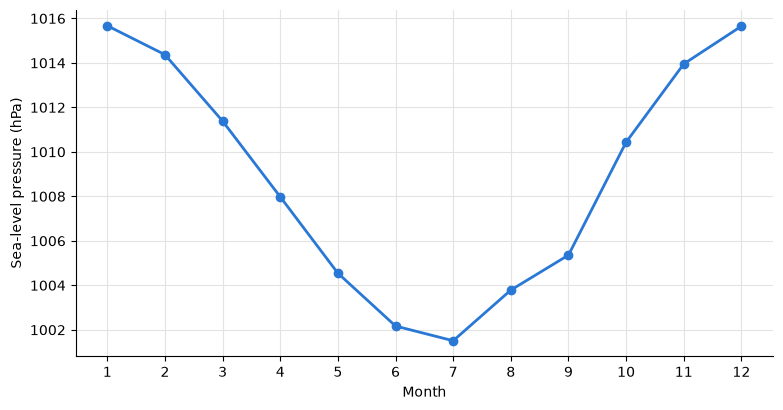

city
Srinagar    -0.92
Amritsar    -0.91
Ludhiana    -0.90
Mumbai      -0.36
Bengaluru   -0.30
Pune        -0.29


In [8]:
by_month = weather.groupby("month")[["temp_mean_c", "pressure_hpa"]].mean()

fig, ax = plt.subplots()
ax.plot(by_month.index, by_month["pressure_hpa"], color=BLUE, linewidth=2, marker="o")
ax.set_xticks(range(1, 13))
ax.set_xlabel("Month")
ax.set_ylabel("Sea-level pressure (hPa)")
plt.show()

within_city = weather.groupby("city")[["temp_mean_c", "pressure_hpa"]].corr().xs("pressure_hpa", level=1)["temp_mean_c"]
print(within_city.sort_values().round(2).iloc[[0, 1, 2, -3, -2, -1]].to_string())

Pressure falls from 1,015.7 hPa in January to 1,001.5 hPa in July, the mirror image of the temperature curve. That is why the correlation table in the README shows -0.76 between temperature and pressure.

Inside a single city the link is strongest in the north, where seasons are sharp (Srinagar -0.92, Amritsar -0.91), and weakest where the temperature hardly changes (Pune -0.29, Bengaluru -0.30). A correlation needs variation to show up, so a weak number in Pune says more about Pune's mild climate than about the physics.

## 7. Does rain come as many small days or a few big ones?

In [9]:
def wettest_ten_share(rain):
    return rain.nlargest(10).sum() / rain.sum()

share = weather.groupby(["city", "year"])["rain_mm"].apply(wettest_ten_share).groupby("city").mean().sort_values()
rainy_days = weather[weather["rain_mm"] >= 2.5].groupby("city").size() / weather["year"].nunique()

table = pd.DataFrame({"rain on 10 wettest days (%)": (share * 100).round(0),
                      "rainy days a year": rainy_days.round(0)})
print(f"average share on the 10 wettest days: {share.mean():.0%}")
table.sort_values("rain on 10 wettest days (%)").iloc[[0, 1, 2, -3, -2, -1]]

average share on the 10 wettest days: 35%

,rain on 10 wettest days (%),rainy days a year
city,,
Kolkata,22.0,141.0
Bengaluru,23.0,106.0
Guwahati,25.0,148.0
Jaipur,45.0,54.0
Ahmedabad,47.0,60.0
Chandigarh,48.0,55.0


On average, a third of a year's rain (35%) arrives on just ten days. In Chandigarh and Ahmedabad it is close to half. Kolkata and Bengaluru spread their rain more evenly. Jaipur has about 54 rainy days a year and Guwahati about 148, counting a day as rainy when it gets 2.5 mm or more.

For anyone planning drainage or water storage, the total matters less than how concentrated it is. Two cities with similar yearly rain can need very different infrastructure.

## 8. Can we tell real weather from made-up numbers?

The first version of this project used a different dataset. Its humidity and pressure looked plausible in charts, but Srinagar came out as humid as Mumbai, and Mumbai's humidity did not rise in the monsoon. Real weather has three habits that random numbers lack, so we test for each:

- memory: today is close to yesterday,
- seasons: the month explains much of the variation,
- places differ: city averages sit further apart than chance would put them.

The first version's files are kept in `data/first_version/` so this comparison can be repeated.

In [10]:
import numpy as np

def realism_scores(table):
    months = pd.to_datetime(table.index).month
    memory = np.median([table[c].autocorr(lag=1) for c in table.columns])
    season = np.median([1 - (table[c] - table[c].groupby(months).transform("mean")).var() / table[c].var()
                        for c in table.columns])
    place = table.mean().std() / table.std().median()
    return round(memory, 3), round(season, 3), round(place, 3)

rows = []
for name in ["temperature", "humidity", "pressure"]:
    old = pd.read_csv(f"../data/first_version/{name}.csv", index_col="datetime")
    rows.append(("first version", name, *realism_scores(old)))
for name, column in [("temperature", "temp_mean_c"), ("humidity", "humidity_pct"), ("pressure", "pressure_hpa")]:
    new = weather.pivot(index="date", columns="city", values=column)
    rows.append(("current", name, *realism_scores(new)))

rng = np.random.default_rng(0)
noise = pd.DataFrame(rng.normal(60, 15, (1826, 30)), index=pd.date_range("2021-01-01", periods=1826))
rows.append(("pure random numbers", "for comparison", *realism_scores(noise)))

pd.DataFrame(rows, columns=["dataset", "variable", "memory", "seasons", "places"])

,dataset,variable,memory,seasons,places
0,first version,temperature,0.980,0.840,0.489
1,first version,humidity,0.002,0.003,0.015
2,first version,pressure,-0.003,0.003,0.019
3,current,temperature,0.979,0.823,0.647
4,current,humidity,0.952,0.673,0.341
5,current,pressure,0.975,0.818,0.238
6,pure random numbers,for comparison,0.006,0.006,0.024


The first version's temperature behaves like weather on all three counts. Its humidity and pressure score close to zero on every one, the same as the column of pure random numbers added for comparison. The current data from Open-Meteo scores high on all three.

This is why the project was rebuilt. `scripts/realism_check.py` runs the same test as part of the pipeline, and `tests/test_checks.py` checks that it tells weather-like data from random numbers.

## Limitations

- Values are model estimates for a grid cell. They understate local extremes, as section 4 shows.
- Five years is enough to compare cities and spot unusual years, and not enough to measure climate trends.
- Our averages are over five years, while IMD compares with a long period average, so percentages are not directly comparable.
- The 30 cities are mostly large ones and leave out Kerala, most of the Himalaya and most of the north-east.

## Sources

- Open-Meteo, [Historical Weather API documentation](https://open-meteo.com/en/docs/historical-weather-api)
- India Meteorological Department, [Monsoon Report 2025](https://mausam.imd.gov.in/imd_latest/monsoon_report_2025_2.pdf)
- India Meteorological Department, Regional Meteorological Centre Chennai, [North-East Monsoon 2022 report](https://mausam.imd.gov.in/chennai/mcdata/ne_monsoon_2022.pdf)
- India Meteorological Department, [Salient features of the 2024 south-west monsoon season, press release of 1 October 2024](https://internal.imd.gov.in/press_release/20241001_pr_3310.pdf)
- India Meteorological Department, [Annual Report 2024](https://metnet.imd.gov.in/docs/imdnews/ANNUAL_REPORT2024English.pdf)
- AIR News, [Several parts of country continue to reel under severe heat wave conditions, 28 May 2024](https://www.newsonair.gov.in/several-parts-of-country-continues-to-reel-under-severe-heat-wave-conditions-breaking-past-records)